# Inference -- any fundus image -> every stage up to PDR

Give it any fundus photo (or a folder of them). Module 1 grades it and segments its lesions,
then Module 2 cascades stage by stage up to stage 4 (PDR): generate the next stage -> re-segment
it with Module 1 -> re-grade it (consistency check) -> feed it forward. Optionally Module 3
captions each panel with the estimated chance of further progression within 2 years.

Unlike notebook 08 (Tianjin patients only, stopping at their real follow-up grade), this needs no
dataset or follow-up image. Wraps `generate_progression.py`.

**Needs:** Module 1 checkpoints (notebooks 02/03) and a Module 2 Generator -- notebook 06 now
copies it to `Thesis_Datasets/module2_runs/<run>/final-G.ckpt` on Drive. Module 3 (notebook 07)
is optional.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
# Free Drive space: the training notebooks save checkpoints and caches here (several GB in total).
# Deleted or overwritten files stay in the Drive Trash and still count -- empty it if space is low.
import shutil as _shutil
try:
    _du = _shutil.disk_usage('/content/drive/MyDrive')
    print(f'Google Drive: {_du.free / 1e9:.1f} GB free of {_du.total / 1e9:.1f} GB')
    if _du.free < 10e9:
        print('\u26a0 Under 10 GB free on Google Drive -- model files may fail to save. Empty the Trash '
              '(drive.google.com/drive/trash) or free space before training.')
except OSError:
    pass

import getpass, os, glob, json
GITHUB_TOKEN = getpass.getpass('GitHub Personal Access Token (repo scope): ')

REPO_OWNER = 'Mieka068'
REPO_NAME = 'DRProgression'
REPO_BRANCH = 'R8-256px-EyePACSGrader'  # <-- round 8; 'R7-GradeControl-Eval' = round 7, 'R6-ShapeFix-Controls' = round 6, 'R5-Round3Baseline-Fixes' = round 5, 'AllModuleEdits-PreFinals' = rounds 3/4, 'mod-2-NonLongIntegration' = the earlier runs
REPO_CODE_SUBDIR = 'M2-DRProgression-VerM-module1-fgadr-poc'

DRIVE_DATA_DIR = '/content/drive/MyDrive/Thesis_Datasets'
assert os.path.isdir(DRIVE_DATA_DIR), f"Not found: {DRIVE_DATA_DIR}"
MODULE2_RUNS_DIR = os.path.join(DRIVE_DATA_DIR, 'module2_runs')
os.makedirs(MODULE2_RUNS_DIR, exist_ok=True)

# Which Module 1 models the pipeline uses -- set the SAME value in notebooks 04_05 and 06-10:
#   'drgnet' -- notebook 11's DRG-Net replication checkpoints (module1_runs/drgnet_replication/)
#   'poc'    -- notebooks 02/03's original POC checkpoints (module1_runs/)
# Everything built from Module 1's outputs (Module 1 caches, Module 2 runs, figures) gets a
# '_drgnet' suffix for 'drgnet', so the two pipelines never overwrite each other's results.
MODULE1_SOURCE = 'drgnet_combined'
assert MODULE1_SOURCE in ('drgnet_combined', 'drgnet', 'poc'), MODULE1_SOURCE
# New Drive folders for this branch's runs: every Module 1 cache / Module 2 / Module 3 folder below
# gets RUN_SUFFIX, so the mod-2-NonLongIntegration results stay untouched for before/after
# comparison. '' = read/write the earlier folders again.
RUN_SUFFIX = '_prefinals'
RUN_TAG = {'drgnet_combined': '_drgnet_comb', 'drgnet': '_drgnet', 'poc': ''}[MODULE1_SOURCE] + RUN_SUFFIX
# Round 4: every Module 1 cache / Module 2 / Module 3 folder ALSO gets ROUND_TAG, so round 3's results
# (no ROUND_TAG) stay untouched for before/after comparison -- the SAME value in notebooks 04_05 and 06-10.
# Model folders (notebook 11) and the laterality file keep RUN_SUFFIX only. '' = round 3's folders.
# Round 5 (branch R5-Round3Baseline-Fixes): round 3's Module 2 settings (128 px, no grader loss, round 3's
# best-epoch rule) + the data fixes (text-safe retina crop, SIFT failures dropped). '_r4' = round 4's folders.
# Round 6 (branch R6-ShapeFix-Controls): reads round 5's Module 1 caches, laterality file, pretrained Generator
# and Module 3 as they are (INPUT_ROUND_TAG); writes figures/outputs to new '_r6' folders (ROUND_TAG).
# Round 7 (branch R7-GradeControl-Eval): same inputs (round 5's), figures/outputs to new '_r7' folders.
# Round 8 (branch R8-256px-EyePACSGrader): 256 px. Module 1 caches, laterality file and Module 3 are round 5's
# (INPUT_ROUND_TAG); notebook 09's pretraining is round 8's own 256 px run (PRETRAIN_RUN_TAG -- round 5's is 128 px);
# the SIFT alignment cache is rebuilt at 256 px in notebook 06 (round 5's is 128 px). Outputs go to new '_r8' folders.
ROUND_TAG = '_r8'
INPUT_ROUND_TAG = '_r5'
BASE_RUN_TAG = RUN_TAG
INPUT_RUN_TAG = BASE_RUN_TAG + INPUT_ROUND_TAG
RUN_TAG = BASE_RUN_TAG + ROUND_TAG
PRETRAIN_RUN_TAG = BASE_RUN_TAG + '_r8'  # notebook 09's pretrained Generator (round 8: 256 px)
# Image preprocessing for every script this notebook runs (fundus_preprocess.py), the same in 04_05-10:
#   DRP_RETINA_CROP '1' = crop to the retina and pad to square before resizing (Tianjin's 3:2 and LongDR's
#     2000x1312 photos were squashed into ovals); '0' = round 3's plain resize.
#   DRP_LONGDR_FOLDER 'FundusImagesColor' = LongDR's raw colour photos. Round 3 used FundusImagesNormalized,
#     on which the lesion segmenters (trained on raw photos) marked 10-30 % of a NORMAL retina as lesion
#     (LBS 0.1-0.34 at grade 0, vs ~0.001 on Tianjin/FIRE) -- 559 of the 917 Module 2 pairs.
os.environ['DRP_RETINA_CROP'] = '1'
os.environ['DRP_LONGDR_FOLDER'] = 'FundusImagesColor'
# Module 2 resolution -- the SAME value in notebooks 06, 08, 09 and 10 (item 4.3; the scripts stop
# with an error on a mismatch).
# Round 4: 'auto' = the size notebook 04_05's grader-resolution check recommends (its
# grader_resolution_check.json in this round's Module 1 cache folder): 256 px when the grader reads real
# Tianjin images clearly better at 256 than at 128 px (kappa +0.05 or more), else 128 (~4x faster). Set a
# number (128 / 256) to override. Run 04_05 to the end BEFORE 09 / 06, so every notebook gets the same size.
MODULE2_IMAGE_SIZE = 256  # round 8: 256 px (notebook 12: EyePACS separation +17 % at 256 vs +7 % at 128); round 5-7: 128; 'auto' = notebook 04_05's recommendation (256 in round 4)
MODULE1_RUNS = os.path.join(DRIVE_DATA_DIR, 'module1_runs', *(['drgnet_replication'] if MODULE1_SOURCE != 'poc' else []))
# Notebook 11 on this branch writes its models to drgnet_replication<RUN_SUFFIX>/ (tiled evaluation,
# 200 segmentation epochs, optional EyePACS grader); use those once they exist.
if MODULE1_SOURCE != 'poc' and os.path.isdir(os.path.join(MODULE1_RUNS + RUN_SUFFIX, 'segmentation')):
    MODULE1_RUNS += RUN_SUFFIX
elif MODULE1_SOURCE != 'poc' and RUN_SUFFIX:
    print(f'\u26a0 {MODULE1_RUNS + RUN_SUFFIX} not found -- using the earlier Module 1 models in {MODULE1_RUNS}. '
          'Run notebook 11 on this branch first for the re-trained ones.')
# Lesion segmenters: <MODULE1_RUNS>/segmentation/<SEG_MODEL_PREFIX><lesion>/model_2.pth.tar --
# FGADR + DDR combined (notebook 11) or FGADR only. The classifier is FGADR's either way.
SEG_MODEL_PREFIX = 'comb_models_' if MODULE1_SOURCE == 'drgnet_combined' else 'models_FGADR_NO_TATL_'
# Round 4: notebook 11's fine-tuned combined segmenters (comb_ft_models_*) once all four exist.
if MODULE1_SOURCE == 'drgnet_combined':
    if all(os.path.isfile(os.path.join(MODULE1_RUNS, 'segmentation', f'comb_ft_models_{_l}', 'model_2.pth.tar'))
           for _l in ('ex', 'he', 'ma', 'se')):
        SEG_MODEL_PREFIX = 'comb_ft_models_'
    elif ROUND_TAG:
        print('\u26a0 Fine-tuned segmenters (comb_ft_models_*) not all on Drive yet -- using the 200-epoch '
              'comb_models_*. Run notebook 11 (RUN["comb_seg_ft"]) first for round 4.')
print('Lesion segmenters:', SEG_MODEL_PREFIX + '<lesion>')
MODULE1_CACHE_DIR = os.path.join(DRIVE_DATA_DIR, 'module1_cache' + INPUT_RUN_TAG)  # round 5's caches (read only)
os.makedirs(MODULE1_CACHE_DIR, exist_ok=True)
print('Module 1 source:', MODULE1_SOURCE, '| models:', MODULE1_RUNS, '| caches:', MODULE1_CACHE_DIR)
if MODULE2_IMAGE_SIZE == 'auto':
    import json as _json
    _res_json = os.path.join(MODULE1_CACHE_DIR, 'grader_resolution_check.json')
    if os.path.isfile(_res_json):
        _res = _json.load(open(_res_json))
        if _res.get('recommended_image_size'):
            MODULE2_IMAGE_SIZE = int(_res['recommended_image_size'])
        else:  # a check file written before the recommended_image_size field
            _gain = max((_res.get('kappa_gain_high_vs_low') or {0: 0}).values())
            MODULE2_IMAGE_SIZE = max(_res['sizes']) if _gain >= 0.05 else min(_res['sizes'])
        print(f'MODULE2_IMAGE_SIZE = {MODULE2_IMAGE_SIZE} (auto, from {_res_json}: {_res.get("recommendation")})')
    else:
        MODULE2_IMAGE_SIZE = 256
        print(f'\u26a0 MODULE2_IMAGE_SIZE = 256 (auto fallback): {_res_json} not found -- run notebook 04_05 to the end '
              'first, or set MODULE2_IMAGE_SIZE by hand. Every Module 2 notebook must use the same size.')

Mounted at /content/drive
Google Drive: 105.1 GB free of 214.7 GB
GitHub Personal Access Token (repo scope): ··········
Lesion segmenters: comb_ft_models_<lesion>
Module 1 source: drgnet_combined | models: /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals | caches: /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals_r5


In [2]:
# Clone this repo. Skips cleanly if already cloned in this runtime.
%cd /content
if not os.path.isdir(f'/content/{REPO_NAME}'):
    !git clone --branch {REPO_BRANCH} https://{GITHUB_TOKEN}@github.com/{REPO_OWNER}/{REPO_NAME}.git {REPO_NAME}
REPO_CODE_DIR = f'/content/{REPO_NAME}/{REPO_CODE_SUBDIR}'
assert os.path.isdir(REPO_CODE_DIR), f"Not found: {REPO_CODE_DIR} -- check REPO_BRANCH/REPO_CODE_SUBDIR above"
%cd {REPO_CODE_DIR}
!pip install -q pandas openpyxl segmentation-models-pytorch matplotlib scipy torchmetrics torch-fidelity

/content
Cloning into 'DRProgression'...
remote: Enumerating objects: 1323, done.
remote: Counting objects: 100% (182/182), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 1323 (delta 166), reused 151 (delta 141), pack-reused 1141 (from 2)
Receiving objects: 100% (1323/1323), 47.30 MiB | 20.21 MiB/s, done.
Resolving deltas: 100% (789/789), done.
/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc


In [3]:
CLASSIFIER_RUN = 'eyepacs'   # Module 1 grader: 'eyepacs' (default, notebook 11) or 'fgadr' -- use the one notebook 04_05's comparison recommends
if not glob.glob(os.path.join(MODULE1_RUNS, 'classification', CLASSIFIER_RUN, 'saves', '*.pt')):
    print(f'\u26a0 No {CLASSIFIER_RUN} grader in {MODULE1_RUNS} yet -- using the FGADR one')
    CLASSIFIER_RUN = 'fgadr'

# Locate the Module 1 classifier + segmentation checkpoints (same discovery logic as
# notebooks 04-08). HE/SE are included automatically once they exist on Drive.
SEG_DIR   = os.path.join(MODULE1_RUNS, 'segmentation')
CLS_SAVES = os.path.join(MODULE1_RUNS, 'classification', CLASSIFIER_RUN, 'saves')
# Classifier input normalisation must match its training config (eyepacs_poc.yaml differs).
CLS_NORM_ARGS = ' --classifier-norm eyepacs' if CLASSIFIER_RUN == 'eyepacs' else ''

# EyePACS: best_validation_weights.pt (picked on the Kaggle public test, kept apart from its test set);
# FGADR: final_weights.pt (its "validation" set IS its test set, so the best-validation pick is optimistic).
_pref  = (['best_validation_weights.pt', 'final_weights.pt'] if CLASSIFIER_RUN == 'eyepacs'
          else ['final_weights.pt', 'best_validation_weights.pt'])
_cands = [os.path.join(CLS_SAVES, n) for n in _pref] + sorted(
    glob.glob(os.path.join(CLS_SAVES, '*.pt')), key=os.path.getmtime, reverse=True)
CLS_CKPT = next((p for p in _cands if os.path.isfile(p)), None)
assert CLS_CKPT, f"No classifier .pt in {CLS_SAVES} -- run notebook 02/03 (MODULE1_SOURCE='poc') or 11 ('drgnet' / 'drgnet_combined') first"

SEG_ARGS = ''
for _lesion in ['EX', 'MA', 'HE', 'SE']:
    _p = os.path.join(SEG_DIR, f'{SEG_MODEL_PREFIX}{_lesion.lower()}', 'model_2.pth.tar')
    if os.path.isfile(_p):
        SEG_ARGS += f' --seg-checkpoint {_lesion}="{_p}"'
    print(f'{_lesion} seg :', _p if os.path.isfile(_p) else 'not trained yet')
assert 'EX=' in SEG_ARGS and 'MA=' in SEG_ARGS, f'EX/MA segmentation checkpoints missing in {SEG_DIR} -- run notebook 03 (poc) or 11 (drgnet) first'
print('classifier:', CLS_CKPT)

# Module 2 Generator: first one found, preferring the EyePACS-pretrained + fine-tuned run, and
# within a run best-G.ckpt (best epoch on held-out pairs) over final-G.ckpt (last epoch).
_gen_cands = [os.path.join(base, run + RUN_TAG, ckpt)
              for run in ('models_poc_tianjin_from_nonlong', 'models_poc_tianjin')
              for base in (MODULE2_RUNS_DIR, f'{REPO_CODE_DIR}/DRForestGAN-v2/stargan')
              for ckpt in ('best-G.ckpt', 'final-G.ckpt')]
# Which Generator to use -- 'finetuned' = notebook 06's best-G.ckpt from this round (round 8, 256 px); 'pretrained' =
# notebook 09's EyePACS-pretrained Generator (round 8, 256 px, no longitudinal fine-tuning); 'round6' = round 6's
# fine-tuned Generator (rounds 6/7's default) -- 128 px only, so not usable in round 8. Each choice has its own output folder.
GENERATOR = 'finetuned'
assert GENERATOR in ('finetuned', 'round6', 'pretrained'), GENERATOR
assert GENERATOR != 'round6' or MODULE2_IMAGE_SIZE == 128, "round 6's Generator is 128 px -- use 'finetuned' or 'pretrained'"
ROUND6_CKPT = os.path.join(DRIVE_DATA_DIR, 'module2_runs', 'models_poc_tianjin_from_nonlong' + BASE_RUN_TAG + '_r6', 'best-G.ckpt')
FOV_MASK = True   # round 6: black out every synthesized step outside the baseline's retina circle
FOV_ARG = ' --fov-mask' if FOV_MASK else ''  # not inline: a Python expression inside !python may not expand
# Round 7: the same cascade clean-up as notebook 06 (use the same values): every step's colours matched to the real
# baseline (COLOR_MATCH; round 6's grey drift). FOV_ERODE / FOV_FEATHER pull the retina mask in / fade its edge -- 0, 0 =
# the baseline's full circle, as in round 6 (4, 3 made the eye ~12 % narrower with a dimmed rim; 2, 0 = 97 % size).
# CASCADE_MODE 'direct' = every stage from the real baseline instead of the previous step (comparison only).
FOV_ERODE, FOV_FEATHER, COLOR_MATCH = 0, 0, True
CASCADE_MODE = 'cascade'
CASCADE_ARGS = ((f' --fov-erode {FOV_ERODE} --fov-feather {FOV_FEATHER}' if FOV_MASK else '')
                + (' --color-match' if COLOR_MATCH else '')
                + (' --cascade-mode direct' if CASCADE_MODE == 'direct' else ''))
OUT_SUFFIX = RUN_TAG + {'finetuned': '', 'round6': '_round6G', 'pretrained': '_pretrained'}[GENERATOR] + ('_direct' if CASCADE_MODE == 'direct' else '')
if GENERATOR == 'finetuned':
    GENERATOR_CKPT = next((p for p in _gen_cands if os.path.isfile(p)), None)
    assert GENERATOR_CKPT, 'No Module 2 best-G/final-G.ckpt found -- run notebook 06 first (same MODULE1_SOURCE)'
elif GENERATOR == 'round6':
    GENERATOR_CKPT = ROUND6_CKPT
    assert os.path.isfile(GENERATOR_CKPT), f'{GENERATOR_CKPT} not found -- round 6\'s notebook 06 output'
else:
    GENERATOR_CKPT = os.path.join(MODULE2_RUNS_DIR, 'nonlong_pretrain' + PRETRAIN_RUN_TAG, 'final-G.ckpt')
    assert os.path.isfile(GENERATOR_CKPT), f'{GENERATOR_CKPT} not found -- this round\'s notebook 09 output'
print('generator :', GENERATOR_CKPT, f'({GENERATOR})')

# Module 3 (optional): notebook 07's run, copied to Drive (module3_runs/module3_runs_poc{RUN_TAG}/), else this runtime.
# Round 6: notebook 07 isn't re-run -- round 5's Module 3 (INPUT_RUN_TAG).
MODULE3_DIR = next((d for d in (os.path.join(DRIVE_DATA_DIR, 'module3_runs', 'module3_runs_poc' + INPUT_RUN_TAG),
                                 f'{REPO_CODE_DIR}/module3/module3_runs_poc')
                    if os.path.isfile(os.path.join(d, 'final-model.ckpt'))), None)
MODULE3_ARGS = ''
if MODULE3_DIR:
    _m3_ckpt = 'best-model.ckpt' if os.path.isfile(os.path.join(MODULE3_DIR, 'best-model.ckpt')) else 'final-model.ckpt'
    MODULE3_ARGS = (f' --module3-checkpoint "{MODULE3_DIR}/{_m3_ckpt}"'
                    f' --module3-thresholds-json "{MODULE3_DIR}/poc_results.json"')
print('module 3  :', MODULE3_ARGS or 'not found -- figures without progression-probability captions')

EX seg : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_ex/model_2.pth.tar
MA seg : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_ma/model_2.pth.tar
HE seg : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_he/model_2.pth.tar
SE seg : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_se/model_2.pth.tar
classifier: /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/classification/eyepacs/saves/best_validation_weights.pt
generator : /content/drive/MyDrive/Thesis_Datasets/module2_runs/models_poc_tianjin_from_nonlong_drgnet_comb_prefinals_r8/best-G.ckpt (finetuned)
module 3  :  --module3-checkpoint "/content/drive/MyDrive/Thesis_Datasets/module3_runs/module3_runs_poc_drgnet_comb_prefinals_r5/best-model.ckpt" --module3-th

In [4]:
# Input: a Drive folder of fundus images, or upload some now if that folder is empty/missing.
# Round 4: use eyes that start at >= mild NPDR (the thesis scope) -- e.g. Tianjin baseline images whose
# clinical grade is mild/moderate NPDR, or FGADR/IDRiD grade-1/2 images; grade-0 inputs are skipped below.
INPUT_DIR = os.path.join(DRIVE_DATA_DIR, 'progression_inputs')
os.makedirs(INPUT_DIR, exist_ok=True)
if not glob.glob(os.path.join(INPUT_DIR, '*')):
    from google.colab import files
    for _name, _data in files.upload().items():
        open(os.path.join(INPUT_DIR, _name), 'wb').write(_data)
print(sorted(os.listdir(INPUT_DIR)))

['00198-7325.jpg']


In [5]:
START_STAGE = None   # None = use Module 1's grade of the input; or force a known clinical grade 0-3
END_STAGE = 4        # 4 = PDR
# Round 4: the thesis scope starts at mild NPDR -- inputs whose start stage is below MIN_START_STAGE are
# skipped (round 3's demo was a grade-0 Tianjin image). 0 = cascade every input.
# Round 6: 0, so the grade-0 demo photo (00198-7325) is cascaded as in rounds 3 and 5 (round 5 set it in Colab).
MIN_START_STAGE = 0
OUT_DIR = os.path.join(DRIVE_DATA_DIR, 'progression_outputs' + OUT_SUFFIX)

_start = f' --start-stage {START_STAGE}' if START_STAGE is not None else ''
%cd {REPO_CODE_DIR}
!python generate_progression.py --image-size {MODULE2_IMAGE_SIZE} --input "{INPUT_DIR}" \
    --generator-checkpoint "{GENERATOR_CKPT}" \
    --classifier-checkpoint "{CLS_CKPT}"{SEG_ARGS}{CLS_NORM_ARGS}{MODULE3_ARGS} \
    --end-stage {END_STAGE}{_start} --min-start-stage {MIN_START_STAGE}{FOV_ARG}{CASCADE_ARGS} --out-dir "{OUT_DIR}"

/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc
Classifier normalisation: eyepacs mean=[0.425753653049469, 0.29737451672554016, 0.21293757855892181] std=[0.27670302987098694, 0.20240527391433716, 0.1686241775751114]
Lesion segmentation: tiled (retina 1280 px, 512 px tiles, stride 384) | retina crop: on
Device: cuda
Generating stage trajectories up to stage 4 for 1 image(s)...
  ✓ 00198-7325: Module 1 grade 0 -> start 0, synthesized up to 4 (consistency 1:x 2:x 3:x 4:ok) -> /content/drive/MyDrive/Thesis_Datasets/progression_outputs_drgnet_comb_prefinals_r8/00198-7325
✓ Done -- outputs in /content/drive/MyDrive/Thesis_Datasets/progression_outputs_drgnet_comb_prefinals_r8



/content/drive/MyDrive/Thesis_Datasets/progression_inputs/00198-7325.jpg: Module 1 grade 0, start stage 0
  stage 0 (No DR): LBS 0.0014 [input]
  stage 1 (Mild NPDR): LBS 0.0539, Module 1 re-grade 0 (NOT consistent)
  stage 2 (Moderate NPDR): LBS 0.0636, Module 1 re-grade 4 (NOT consistent)
  stage 3 (Severe NPDR): LBS 0.0668, Module 1 re-grade 4 (NOT consistent)
  stage 4 (PDR): LBS 0.0681, Module 1 re-grade 4 (consistent)


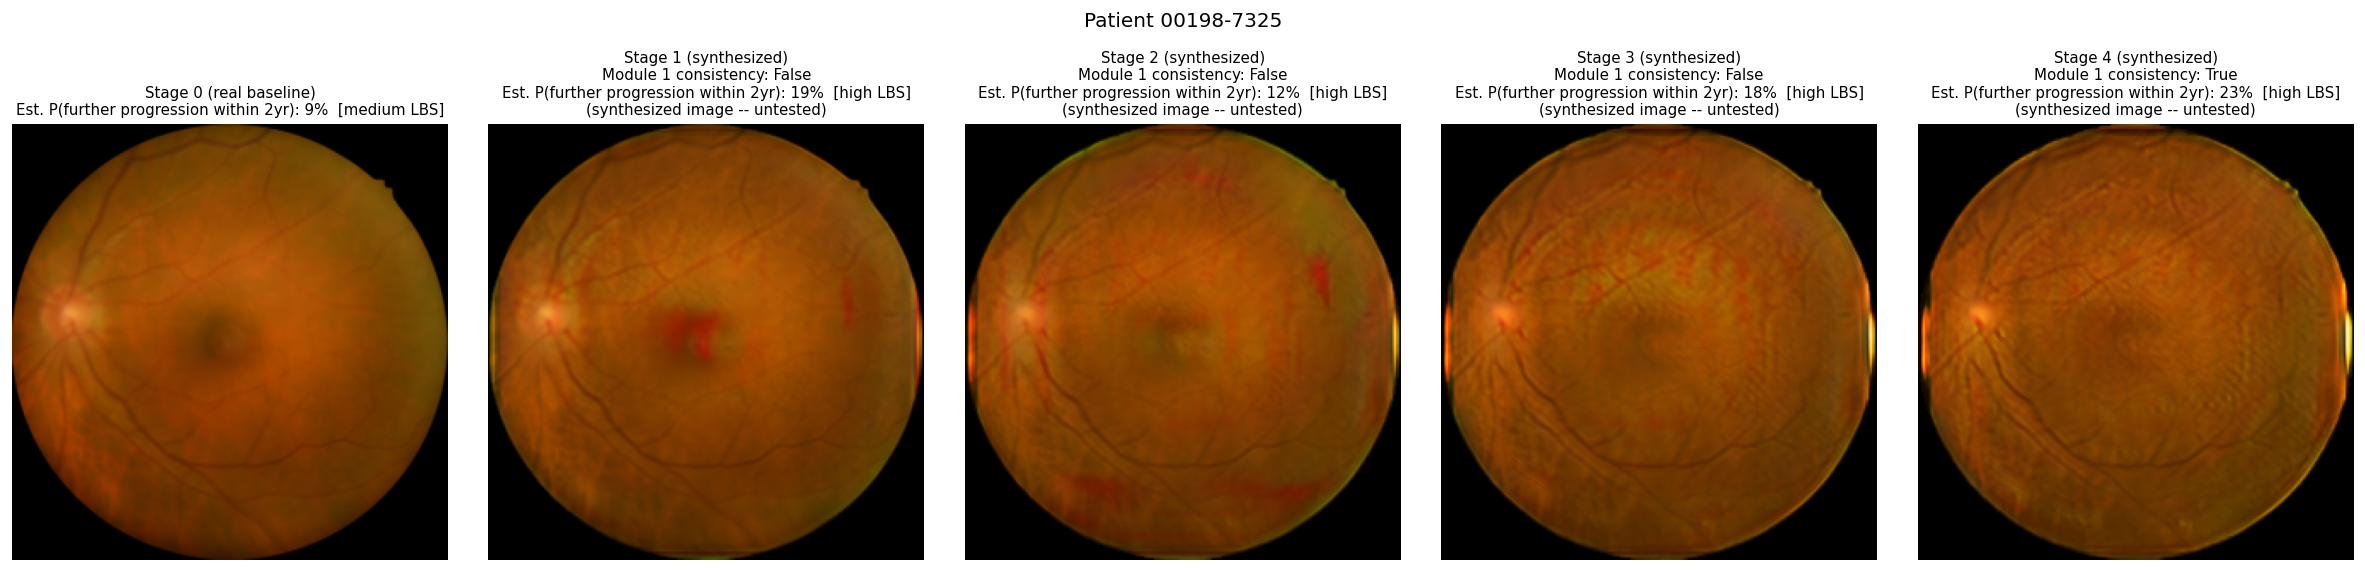

In [6]:
from IPython.display import Image as IPImage, display
_all = os.path.join(OUT_DIR, 'all_trajectories.json')
if os.path.isfile(_all):
    for _s in json.load(open(_all)):
        if _s.get('skipped'):
            print(f"skipped {_s['input']}: {_s['skipped']}")
for _fig in sorted(glob.glob(f'{OUT_DIR}/*/trajectory.png')):
    _summary = json.load(open(_fig.replace('trajectory.png', 'trajectory.json')))
    print(f"\n{_summary['input']}: Module 1 grade {_summary['module1_input_grade']}, start stage {_summary['start_stage']}")
    for _s in _summary['steps']:
        print(f"  stage {_s['stage']} ({_s['stage_name']}): LBS {_s['lbs']:.4f}"
              + (f", Module 1 re-grade {_s['module1_grade']} ({'consistent' if _s['module1_consistent'] else 'NOT consistent'})" if _s['synthesized'] else ' [input]'))
    display(IPImage(_fig))

## Caveats

- Module 1 does not segment neovascularisation (NV), the defining sign of PDR, so stage-4
  images mostly show heavier EX/HE/MA/SE unless the Generator learned NV from EyePACS stage-4
  images during pretraining (notebook 09).
- Each step builds on the previous synthesized image, so errors compound -- the PDR panel is
  the least reliable.
- "Module 1 re-grade ... NOT consistent" can mean the synthesized image is implausible, or that
  Module 1 is unreliable on synthesized images, or both.
- Module 3 captions on synthesized panels are outside its training distribution (untested).

## Before closing the runtime

Files written to Drive upload in the background. Run this last cell and wait for the ✓ before
disconnecting or deleting the runtime -- otherwise large files written at the end (model weights,
caches) can be lost.

In [7]:
from google.colab import drive
drive.flush_and_unmount()
print('✓ Everything is uploaded to Google Drive -- safe to disconnect the runtime.')

✓ Everything is uploaded to Google Drive -- safe to disconnect the runtime.
